# Homework 3: Classification and clustering

This assignment has 3 parts. Each part is graded as listed in its heading.

## Homework 3.1 (32 points)

**Learning objectives:**

In this assignment, we will delve into methods for classification.  We will explore:

*   ROC curves
*   Linear discriminant analysis


---

### Part 0
Load the same libraries that we used in previous homeworks.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)

We'll also briefly introduce the `pandas` package here.  `pandas` includes powerful functionality for more complex data structures that is used widely for data science applications

*   `import pandas as pd`

As always, now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 1 (2 points)
*   Load the Fisher's Iris dataset.  This famous dataset includes measurements from three related species of flowers. These data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework3/FishersIris.csv

*    To do this, use the pandas function `pd.read_csv` to create a a `pandas` DataFrame

In [ ]:
# Your code here


Let's explore this object using some common `pandas` methods.

*   Use the `head` method to display the data in the first 5 entries of `df`.

In [ ]:
# Your code here


*   Use the `describe` method to display some summary statistics for the DataFrame object you created.

In [ ]:
# Your code here


*   Use the `info` method to display some additional information about the DataFrame object you created.

In [ ]:
# Your code here


---
### Part 2 (2 points)
While pandas dataframes can be very handy in many advanced applications, we don't need their functionality here.  Instead, create some numpy arrays for easy access to the data contained in `df`.  You can access columns of data in a dataframe by their column label.  For example, `df['sepallength']` returns the first column of the dataframe.

*   Create a numpy array called `sl` containing sepal length measurements.
*   Create a numpy array called `sw` containing sepal width meaasurements.
*   Create a numpy array called `species` that contains the species from which the above measurements were taken.
*   Create a numpy array called `snum` in which the three species names in `species` are converted into the numbers 0, 1, and 2 (i.e. `0` for *Iris setosa*, `1` for *Iris versicolor*, etc.).  `np.unique` is a useful function for this application (examine the optional output arguments).

Familiarize yourself with the organization of these variables.  We'll use them throughout.

*   Finally, plot `sl`, `sw`, and `snum`.

In [ ]:
# Your code here


---
### Part 3 (2 points)

Plot histograms of sepal length and sepal width for *Iris setosa* and *Iris versicolor* as shown below using the numpy arrays we created.

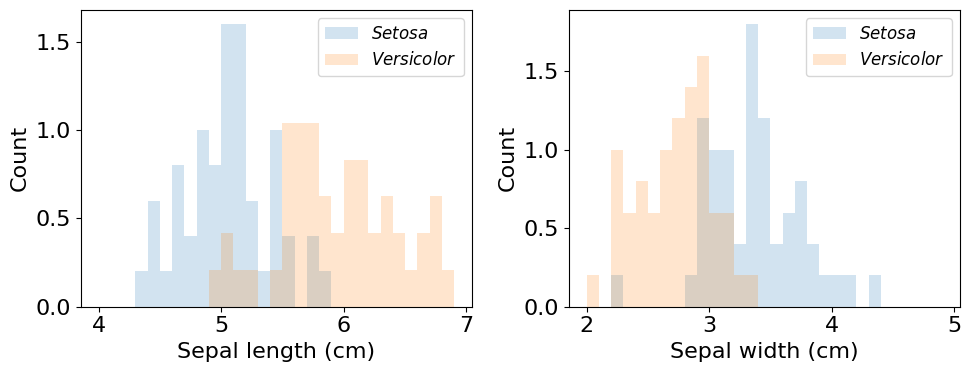

In [ ]:
# Your code here


---
### Part 4 (2 points)

Let's see how discriminable *Iris setosa* and *Iris versicolor* are based on sepal length or based on sepal width using ROC curves.  

*   Write a function called `ROC` for calculating the quantities we need to create an ROC curve.

This function should be structured as follows:

**Inputs**  
`data`: a numpy array containing the measurements upon which classification is based.

`group`: a numpy array the same size as `data` containing 0's for entries in `data` associated with class 0 (i.e. *setosa*) and 1's for entries in `data` associated with class 1 (*versicolor*).

**Outputs**

`tp`: the true positive rate for each threshold.

`fp`: the false positive rate for each threshold.

`AUC`: The area under the ROC curve.

**NOTES**

(1) To calculate the above, you will first need to create a numpy array of threshold values.  These threshold values should vary between `min(data)` and `max(data)` in 50 steps.

(2) List comprehensions are an efficient method to calculate `tp` and `fp`.

(3) The numpy method `trapz` might be helpful for calculating the AUC.

🚩 **Common mistake:** Thresholds that increase from `min(data)` to `max(data)` make `tp` and `fp` decrease, so passing them to `np.trapz` in that order gives an AUC with the wrong sign. Print your AUC and check that it makes sense (between 0 and 1) before trusting it.

See the lecture notes on [ROC curves](https://depasquale-lab.github.io/BE559/lectures/Lecture3.1.html#roc-curves-receiver-operating-characteristic) for how the curve is built.

In [ ]:
# Your code here


---
### Part 5 (2 points)

Now let's calculate and display our ROC curves.

*   Use your `ROC` function to calculate the true positive rate, false positive rate, and AUC when sepal length or sepal width are used for classification.  Store these values.

*   Print the AUC value associated with each feature

*   On one set of axes, plot ROC curves associated with sepal length and sepal width.  Label the curves. Include the diagonal line y=x.

In [ ]:
# Your code here


---
### Part 6 (2 points)

Let's take a look at the data in 2D.

*   Plot sepal width vs. sepal length of all specimens in the dataset.  Plot blue dots for specimens of *Iris setosa* and red dots for specimens of *Iris versicolor.*
*   Use `axis('equal')` to set the x-axis and y-axis scales to be equal.

Now, calculate the coordinates of the centroids of both groups of data. In addition, calculate the coordinates of the middle of the line connecting the centroids (the mean of the centroids).

*   Plot the loction of the centroids as large yellow dots with a line connecting them.  In addition, plot the location of the midpoint between the two centroids as a yellow 'x'.

In [ ]:
# Your code here


---
### Part 7 (2 points)

Now, we will use linear discriminant analysis (LDA) to classify specimens as *Iris setosa* or *Iris versicolor* in  higher dimensions (i.e. based on both sepal length and width).

LDA uses a discriminant function of the  form:

$ y(x) = W^Tx + {\omega}_0 $

where:

$ W = {\Sigma}^{-1} (\mu_2 - \mu_1) $ is the decision vector, the vector orthogonal to the decision boundary.

Importantly, ${\Sigma}^{-1}$ is the within-class covariance matrix, assumed to be the same for both classes.  To calculate ${\Sigma}^{-1}$, you must subtract the class mean from each data point before calculating the covariance matrix.

*   Plot the data after the within-class means have been subtracted.
*   Calculate $W$ as described above and print it.

We'll deal with ${\omega}_0 $ later.

🚩 **Common mistake:** `np.cov` treats each *row* as a variable. Passing an N×2 array of samples silently returns an N×N matrix instead of the 2×2 covariance you want, so check the shape of what you get back and transpose if needed.

See the lecture notes on [Fisher's linear discriminant](https://depasquale-lab.github.io/BE559/lectures/Lecture3.1.html#fisher-s-linear-discriminant) for the derivation of $W$.

In [ ]:
# Your code here


---
### Part 8 (4 points)

Let's assume that $w_0$ is chosen so that the projection of the midpoint between the two class centroids onto the decision vector is equal to zero.

Write three functions as follows:

1) A function that takes x coordinates (sepal length values; a Nx1 numpy array) as inputs and returns the y-position (sepal width values) of a line parallel to the decision vector passing through the midpoint between the class centroids.  This function will also require as input arguments the decision vector itself (1x2 numpy array) and the location of the midpoint (1x2 numpy array).

2) A function that takes x coordinates (Nx1 numpy array) as input and returns the y-position of the decision boundary under the assumption that it passes through the centroid midpoint.  This function should require the same input arguments as (1).

3) A function that takes as input data points (Nx2 numpy array), the decision vector (1x2 numpy array), and the centroid midpoint (1x2 numpy array) and returns the coordinates of the projection of the data points onto the line parallel to the decision vector passing through the centroid midpoint.

In [ ]:
# Your code here


---
### Part 9 (4 points)

On a single axes, plot all of the below, as shown in the example figure.
*   The data, as in **Part 6**.
*   A line connecting the class centroids.
*   The decision boundary.
*   The line parallel to the decision vector passing through the centroid midpoint.
*   The projection of the data points onto this line as open circles.

In [ ]:
# Your code here


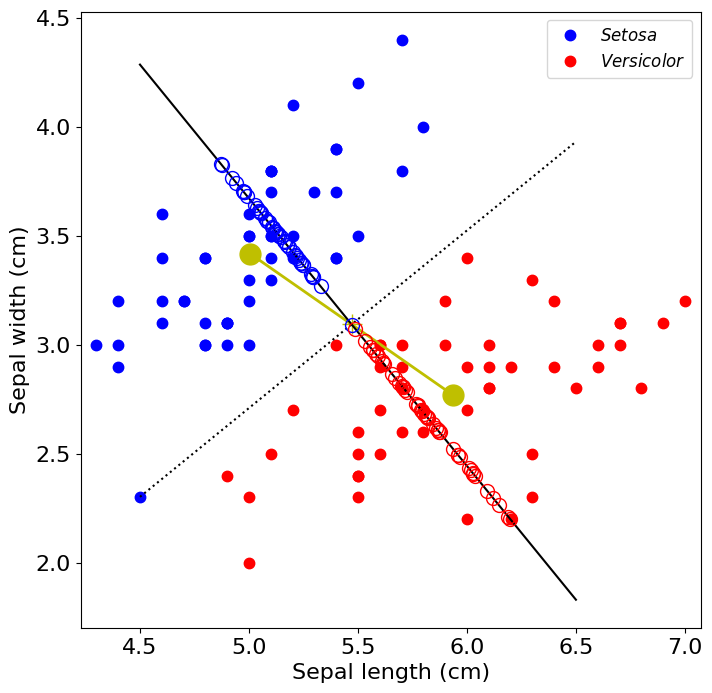

In [ ]:
# Your code here


---
### Part 10 (2 points)

Write a function to calculate

$ y(x) = W^Tx + {\omega}_0 $

$y(x)$ is the distance between the decision boundary (i.e. the projection of the centroid midpoint onto the decision vector) and the projection of a data point, $x$, onto the decision vector.

This function should take as input arguments: data points ($x$; an Nx2 numpy array), the decision vector ($W$; a 1x2 numpy array), and the centroid midpoint (1x2 numpy array used to calculate $w_0$).


In [ ]:
# Your code here


---
### Part 11 (2 points)

Determine the accuracy of classification of these data with LDA.

Use the function above to calculate $y(x)$ for the measurements of *Iris setosa* and *Iris versicolor*.

*   Plot histograms of $y(x)$ for *Iris setosa* and *Iris versicolor*.  
*   Plot ROC curves for classification based on (1) sepal length, (2) sepal width, and (3) $y(x)$.
*   Calculate the AUC for classification of these species using $y(x)$ and display it.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 12 (2 points)

Now, let's apply scikit-learn's version of LDA to our classification problem and see how it compares.

Use the following code to import the `sklearn` package for LDA
*   `from sklearn.discriminant_analysis import LinearDiscriminantAnalysis`

*   Create a `LinearDiscriminantAnalysis` object and then use its `fit` method to determine the parameters of the discriminant function.

*   Use the `decision_function` method to determine the projection of the data onto the decision vector ($y(x)$).

*   As above, plot histograms of $y(x)$ (this time calclulated with `sklearn`) on one axis and, in a second axis, ROC curves for sepal length, sepal width, $y(x)$ (your version), and $y(x)$ (`sklearn` version).

*   Calculate the AUC for classification of these species using $y(x)$ (`sklearn version`) and display it.

In [ ]:
# Your code here


In [ ]:
# Your code here



<font color='red'>**SHORT ANSWER (4 points):** Explain why the decision vector is not aligned with the vector connecting class centroids and how this relates to qualitative features of the data.  Under what conditions would they be aligned?</font>  

## Homework 3.2 (36 points)

**Learning objectives:**

In this assignment, we will continue our examination of methods for data classification. We will explore:

*   Probabilistic discriminitive models
*   Naive Bayes classification


---

### Part 1
Load the same libraries that we used in previous homeworks.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)

*   `from sklearn.discriminant_analysis import LinearDiscriminantAnalysis`
*   `import pandas as pd`

As always, now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 2 (2 points)

First, we will continue to examine Fisher's linear discriminant, and see how we can compute the conditional probabilities of data points belonging to different classes, $P(Class | X)$.

*   Load the Fisher's Iris dataset.  This famous dataset includes measurements from three related species of flowers. These data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework3/FishersIris.csv

*    To do this, use the pandas function `pd.read_csv` to create a `pandas` DataFrame.
*    Construct the variables **`sl`**, **`sw`**, and **`snum`** in the same way as described in *Homework 3.1*.
*    Filter the entries in the three variables above so as only to include data for *Iris setosa* and *Iris versicolor* (i.e. only keep entries where **`snum`** < 2).
*    It will also be helpful to create an additional variable **`meas`**, in which **`sl`** and **`sw`** are combined into a 2xN matrix, where N is the number of measurements.  


In [ ]:
# Your code here


---
### Part 3 (4 points)

Write a function to perform linear discriminant analysis (LDA) as in *Homework 3.1*.  This function should accept **`meas`** and **`snum`** as input arguments and return:

*   **`mu`**: A 2x2 matrix containing the coordinates of the centroid of class 1 (row 1) and centroid of class 2 (row 2).

*   **`C`**: The within-class covariance matrix of your data.

*   **`vec`**: The (1x2) discriminant vector.

Print the values in vec to ensure you get the same answer as last time.

In [ ]:
# Your code here


---
### Part 4 (4 points)

Remember that

$P(C_2| x) = \sigma(-a)$

where

$a = W^Tx - w_0$

with

$W = \Sigma^{-1}(\mu_2-\mu_1)$ (the projection along the LDA vector)

$w_0 = -{\frac{1}{2}} \mu_1^T\Sigma^{-1}\mu_1 + {\frac{1}{2}} \mu_2^T\Sigma^{-1}\mu_2 + ln{\frac{P(C_1)}{P(C_2)}}$ (the threshold that separates classes along the vector)

*   Calculate $P(Iris-versicolor| x)$.
*   In the first axes, plot this probability as a function of $a$ for your data points over the corresponding logistic function.
*   In the second axes, use `matplotlib`'s `scatter` method to plot sepal width vs. sepal length and color each point according to $P(Iris-versicolor| x)$. Set `cmap='coolwarm'` and use `fig.colorbar` to show the color scale.

See the lecture notes on [deriving the class posterior from a generative model](https://depasquale-lab.github.io/BE559/lectures/Lecture3.2.html#deriving-p-c-1-mid-x-from-a-generative-model) for where the logistic form comes from.

In [ ]:
# Your code here


Great!  Now we see how we can calculate the probability that each data point belongs to each class.  Here, Our results are not cross-validated.  Our probabilistic classifier is being applied to the same data used to construct the classifier.

---
### Part 5 (2 points)

Next, we will construct a **naive Bayes classifier** and use it to classify tweets.  We will use two datasets:

1) The tweets of Donald Trump

2) Tweets about Covid-19

We will construct a probabilistic discriminant function that gives us the probability of tweets belonging to each set.

*   Use `pd.read_csv` to load the following datasets into two dataframes

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework3/Corona_NLP_train.csv
https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework3/realdonaldtrump.csv

**NOTE:**  For the first dataset, you will also have to set `encoding='latin-1'` for the tweets to be read correctly.

*   Create numpy arrays called `set1tweets` and `set2tweets` from the appropriate column of each dataframe (i.e. the one containing the tweet text).

In [ ]:
# Your code here


Below is a function that we'll use to clean up our tweets.  It makes all of the text lowercase, and removes common words, words that would be unfair to use, special characters, URLs, etc.

In [ ]:
import re
stopwords = ["that", "have", "be", "i", "with", "we", "you", "for", "on", "an", "a", "of", "and", "in", "the", "to", "from", "at", "is", "are", "it", "as", "by", "com", "or", "amp", "s", \
             "not", "all", "will", "my", "they", "was", "this", "has", "your", "our", "realdonaldtrump", "donald", "trump", "covid", "19"]

def clean_tweet(tweet):
    if type(tweet) == float:
        return ""
    temp = tweet.lower()
    temp = re.sub('([A-Za-z]+)[\'`]([A-Za-z]+)', r'\1'r'\2', temp)
    temp = re.sub("@[A-Za-z0-9_]+","", temp)
    temp = re.sub("#[A-Za-z0-9_]+","", temp)
    temp = re.sub("\[A-Za-z0-9_.]+","", temp)
    temp = re.sub(r'http\S+', '', temp)
    temp = re.sub('[()!?&]', ' ', temp)
    temp = re.sub('\[.*?\]',' ', temp)
    temp = re.sub("[^a-z0-9]"," ", temp)
    temp = temp.split()
    temp = [w for w in temp if not w in stopwords]
    temp = " ".join(word for word in temp)
    return temp

---
### Part 6 (4 points)

Set the random seed to 5.

Create training and testing sets for each class.  From each set of tweets, randomly select 1000 entries (without replacement) as the test set.  As before, you can use `np.random.choice`.  Store them in variables called `test1` and `test2`.  Store the remaining tweets in variables called `train1` and `train2`.  

🚩 **Common mistake:** `np.random.choice` samples *with* replacement by default, so a test set can contain duplicate tweets. Set `replace=False`, and build the training set from the indices that were not chosen so no test tweet leaks into training.

In [ ]:
# Your code here


---
### Part 7 (2 points)

For each tweet in each training set, use your `clean_tweet` function to clean up the text and the `.split(' ')` method to split each tweet at whitespaces into its component words.  For each training set, create a list of lists of the words.  The variable should have the same number of elements as there are tweets in the training set, and each entry in the list should contain all of the words in the tweet in separate elements.

This can be done efficiently with a list comprehension.

In [ ]:
# Your code here


---
### Part 8 (2 points)

*   Use the function below to create a counter object for each set that contains the number of occurrences of each word in each dataset.  This object is a type of dictionary - a python data type that stores key:value pairs.  In this case, the keys are the words in the dataset and the values are the number of occurrences.

*   Use the `most_common` method to display the 20 most common words in each dataset and the number of times they were found.

In [ ]:
from collections import Counter

def count_words(word_array):

    all_words = []

    for tweet in word_array:
        all_words += tweet
    c = Counter(all_words)

    return(c)


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 9 (4 points)

Write a function that computes $log(\frac{P(Trump| x)}{P(Covid| x)})$ using a naive Bayes classifier.

The main input to this function should be an array of words in a single tweet. You will also need to input both set counter objects, and anything you might need to calculate $P(Class)$.

Recall that:

$P(Class| x) \propto P(Class)P(x_1|Class)P(x_2|Class)\cdot\cdot\cdot P(x_n|Class)$


To calculate each probability, you will need to compute:

$P(Class)$: The number of tweets in the class divided by the total number of tweets in both classes (the prior probability).

$P(X_i|Class)$: the probability of the $ith$ word in the tweet being randomly selected from all of the words observed in the Class.  

To calculate the conditional probability, divide the number of occurrences of the word in the class (plus one to avoid multiplying-by-zeros) by the total number of words in the class (i.e. the sum of the counts for all words).  A counter object has a `.values` method that makes this easy to calculate.

🚩 **Common mistake:** Multiplying many small word probabilities together underflows to exactly 0 for long tweets, which makes the ratio meaningless. Add the logarithms of the probabilities instead of multiplying the probabilities.

See the lecture notes on [naive Bayes](https://depasquale-lab.github.io/BE559/lectures/Lecture3.2.html#naive-bayes) for the classifier.

In [ ]:
# Your code here


---
### Part 10 (2 points)

Write a function that iterates over all of the tweets in a list of tweets and for each tweet calculates $log(\frac{P(Trump| x)}{P(Covid| x)})$ (the "log odds") for each tweet using the function from **Part 9**.  This function should return an array the length of the list of tweets that contains all of the log odds values.

Call this function with each test set to determine the log odds of the tweets in each set.

In [ ]:
# Your code here


---
### Part 10 (2 points)

Plot a histogram of the log odds of tweets in the trump test set and the covid test set.

In [ ]:
# Your code here


---
### Part 11 (2 points)

Calculate the true positive rate, false positive rate, true negative rate, and false negative rate and display the values.  Note that if $P(A)<P(B)$, then $log(\frac{P(B)}{P(A)})$ will be a positive number.

Calculate the classification accuracy and display it.

In [ ]:
# Your code here


---
### Part 12 (2 points)

Display the following tweets from the Covid test set:
*   The 2 most likely to be from the Covid set.
*   The 2 least likely to be from the Covid set.

Display the following tweets from the Trump test set:
*   The 2 most likely to be from the Trump set.
*   The 2 least likely to be from the Trump set.

The numpy method `argsort` is useful for accomplishing this.

In [ ]:
# Your code here



<font color='red'>**SHORT ANSWER (4 points):** A Naive Bayes classifier assumes no covariance between features.  Would you expect features to covary in this dataset?  Why or why not?</font>  

## Homework 3.3 (28 points)

**Learning objectives:**

In this assignment, we will learn about:

*   K-means clustering
*   Expectation maximization



---

### Part 1
Load the same libraries that we used in previous homeworks.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `import pandas as pd`

Load the following two libraries as well as follows:

`from sklearn.cluster import KMeans`

`from sklearn.datasets import make_blobs`


As always, now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 2 (2 points)

First, create some data to cluster.  We'll use the `make_blobs` function for this purpose.  Create a dataset using the following parameters:

`n_samples=300`

`centers=4`

`cluster_std=0.7`

`random_state=0`

Use the `matplotlib` method `scatter` to display the datapoints.  Ensure that the x- and y- axes have equal scales as in *Homework 3.1*.


In [ ]:
# Your code here


In [ ]:
# Your code here


OK!  Lets cluster these data using k-means.  

---
### Part 3 (2 points)

*   Since we know that we created a dataset with 4 blobs, we'll take k=4.
*   Initialize the four cluster centers.  Create a 4x2 array containing the location of the 4 cluster centroids.  In principle, we could initialize the with random numbers, but we'll use the following points:

(1,  2)
(1,  1)
(-1, 2)
(-1, 1)

*   Plot the data in blue and the initial cluster centers in red.


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 4 (4 points)

Write a function, called `clusterAssignment`, that finds the closest centroid to a datapoint.  This function should accept a data point and the location of the cluster centroids as inputs and should return the cluster number whose associated centroid is closest to the data point.

This function will be used to determine the cluster assignments, $r_{n,k}$, based on assumptions of the cluster centroids, $\mu_k$.

In [ ]:
# Your code here


---
### Part 5 (4 points)

Write a function, `calculateCentroids` that updates the cluster centroids, $\mu_k$, given cluster assignments, $r_{n,k}$.  This function should accept an Nx2 array of points and an Nx1 array of cluster assignments and return a kx2 array containing the cluster centroids.

In [ ]:
# Your code here


---
### Part 6 (2 points)

Use `clusterAssignment` to find the cluster associated with every data point, given our initial guesses of cluster centroids.  Use a list comprehension.

Use the `scatter` method to plot the data points and cluster centroids, as shown below.  We use `scatter` here instead of `plot` because it lets us define the color of every point plotted using the argument `c`.  For example, you could set `c=clusters`, where `clusters` are your cluster assignments, to set the color of each point to be an integer from 0 to 3.  In this case, integer cluster assignments will be mapped automatically to colors by `scatter` using the default colormap.

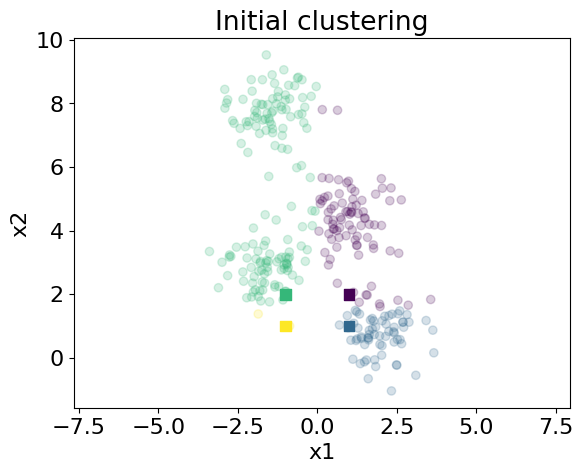

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 7 (4 points)

Now, let's write the k-means algorithm with the functions we wrote.

*   Write a `while` loop to repeat the steps of the k-means algorithm.  This loop should execute until the centroids remain the same on consecutive iterations.

Inside the `while` loop, do the following:

*   Using the function `clusterAssignment`, find the cluster whose centroid is closest to each datapoint (E-step).
*   Using the function `calculateCentroids`, update the cluster centroids based on the current cluster assignments (M-step).
*   Check whether the updated centroids are all identical the centroids defined on the previous iteration of the loop (or, on the first iteration, the initial conditions).  If they are identical, do not continue the while loop.
*   As in Part 6, use `scatter` to display the data points and cluster centroids, colored by their cluster assignment.

Within the while loop, also calculate the value of the k-means objective function, J, after each E-step and each M-step and make a plot of J as it converges.

🚩 **Common mistake:** Writing `old = centroids` does not copy the array; both names point to the same data, so a comparison between them is always "identical" and the loop stops after one pass. Use `.copy()` to keep the previous centroids.

See the lecture notes on [the K-means algorithm](https://depasquale-lab.github.io/BE559/lectures/Lecture3.4.html#the-k-means-algorithm) for the E- and M-steps.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 8 (2 points)

Now, use scikit-learn to perform k-means clustering.  

*   Import KMeans from sklearn.cluster
*   Create a KMeans object and set `n_clusters=4` and `init=c_init`.  We also only want to run the althorigthm once with a single set of initial conditions, and so set `n_init=1`.
*   Use the `fit` and `predict` methods to run k-means on your data.
*   Plot the data and centroids and color them according to cluster membership as in **Part 7**.




In [ ]:
# Your code here


In [ ]:
# Your code here



<font color='red'>**SHORT ANSWER (4 points):**Why do we use an iterative algorithm (similar to Expectation-Maximization) to determine cluster assignments in k-Means?</font>  


<font color='red'>**SHORT ANSWER (4 points):** Describe what you would need to modify in the code you've written (not the sklearn version) to cluster these data using a Gaussian Mixture Model instead of k-Means.</font>  